In [2]:
import numpy as np
import matplotlib.pyplot as plt

fs = 200
duration = 5
N = fs * duration
t = np.arange(N) / fs
# Useful robot motion
clean = (np.sin(2*np.pi*1*t) + 0.4*np.sin(2*np.pi*3*t))
# Reference signal
x_ref = np.sin(2 * np.pi * 65 * t)
# Changing interefence amplitude
amplitude = np.where(t < 2.5, 0.6, 0.2)
noise = amplitude * x_ref
# Noisy measurement
d = clean + noise

Since the reference has the same frequency and phase as the interference, so one-tap LMS is appropriate for this experiment

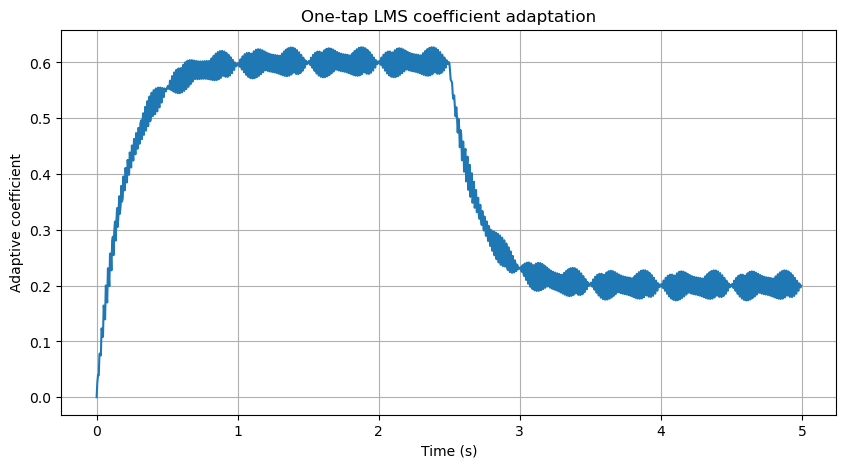

In [3]:
mu = 0.05
w = 0.0
y = np.zeros(N)
e = np.zeros(N)
w_history = np.zeros(N)
for n in range(N):
    y[n] = w * x_ref[n]
    e[n] = d[n] - y[n]
    w = w + mu * e[n] * x_ref[n]
    w_history[n] = w
plt.figure(figsize=(10, 5))
plt.plot(t, w_history)
plt.xlabel("Time (s)")
plt.ylabel("Adaptive coefficient")
plt.title("One-tap LMS coefficient adaptation")
plt.grid(True)
plt.show()

The coefficient approaches 0.6 before 2.5 seconds and after the interference changes it moves toward 0.2

So, LMS does not need to know when the changes happen

This behavior is called adaptive tracking

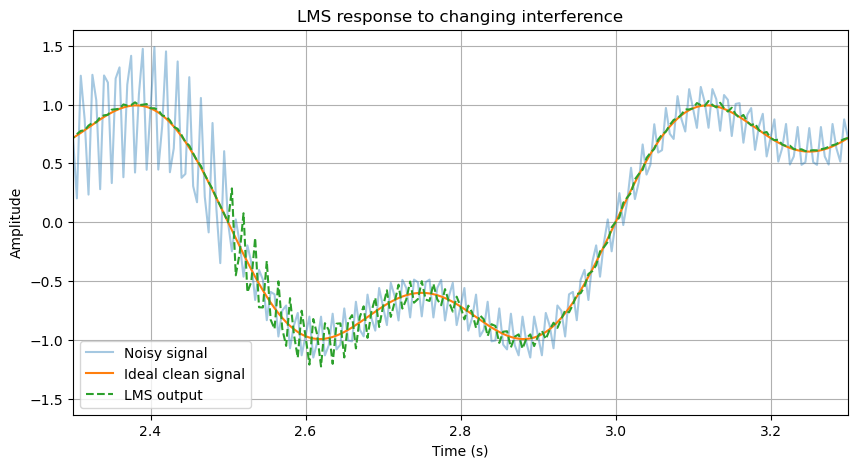

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(t, d, label = "Noisy signal", alpha=0.4)
plt.plot(t, clean, label="Ideal clean signal")
plt.plot(t, e, label="LMS output", linestyle="--")
plt.xlim(2.3, 3.3)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("LMS response to changing interference")
plt.legend()
plt.grid(True)
plt.show()

Immediately after 2 seconds the LMS still has its old coefficients and this produces a temporary error in the filtered output

Around 3.2 Seconds the coefficient is close to 0.2, so the filtered output is close to the clean signal more accurately

In [7]:
# Measuring tracking performance using RMSE
periods = [("Before change", 1.5, 2.5), ("During change", 2.5, 2.8), ("After change", 3.2, 5.0)]
for name, start, end in periods:
    mask = (t >= start) & (t <= end)
    rmse_noisy = np.sqrt(np.mean((d[mask] - clean[mask]) ** 2))
    rmse_lms = np.sqrt(np.mean((e[mask] - clean[mask]) ** 2))

    print(name, ":")
    print(f"RMSE before filtering = {rmse_noisy:.4f}")
    print(f"RMSE after LMS = {rmse_lms:.4f}")
    print()

Before change :
RMSE before filtering = 0.4232
RMSE after LMS = 0.0126

During change :
RMSE before filtering = 0.1403
RMSE after LMS = 0.1594

After change :
RMSE before filtering = 0.1414
RMSE after LMS = 0.0126



During adaptation the LMS RMSE increases because the coefficient has not yet reached its new value

Now, I want to investigate whether changing the LMS step size can make the filter track changes faster without causing excessive fluctuations

    
    


step size = 0.01
During adaptation : RMSE = 0.21409725697397844
After adaptation : RMSE = 0.06408063018275188

step size = 0.05
During adaptation : RMSE = 0.15935419977409487
After adaptation : RMSE = 0.01262042443734417

step size = 0.15
During adaptation : RMSE = 0.10247464564694017
After adaptation : RMSE = 0.038531671407792144


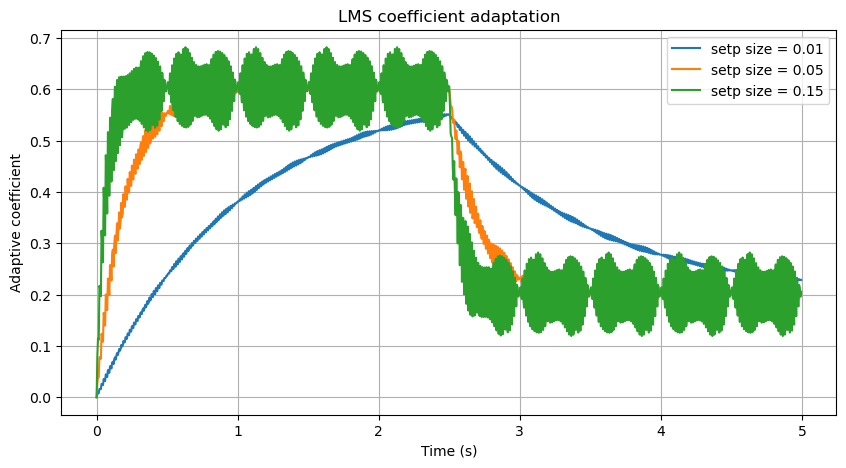

In [16]:
# Effect of Step Size on Tracking Performance
step_sizes = [0.01, 0.05, 0.15]
plt.figure(figsize=(10, 5))
for mu in step_sizes:
    w = 0.0
    y = np.zeros(N)
    e = np.zeros(N)
    w_history = np.zeros(N)
    for n in range(N):
        y[n] = w * x_ref[n]
        e[n] = d[n] - y[n]
        w = w + mu * e[n] * x_ref[n]
        w_history[n] = w

    plt.plot(t, w_history, label=f"setp size = {mu}")
    periods = [("During adaptation", 2.5, 2.8), ("After adaptation", 3.2, 5.0)]
    print()
    print(f"step size = {mu}")
    for name, start, end in periods:
        mask = (t >= start) & (t <= end)
        rmse = np.sqrt(np.mean((e[mask] - clean[mask]) ** 2))
        print(f"{name} : RMSE = {rmse}")
plt.legend()
plt.xlabel("Time (s)")
plt.ylabel("Adaptive coefficient")
plt.title("LMS coefficient adaptation")
plt.grid(True)
plt.show()
    
    

This shows that the step size that adapts fastest is not necessarily the most accurate after adaptation

So mu=0.15 is preferable if rapid recovery is our highest priority, while mu=0.05 is preferable if we prioritize low error after adaptation.

### Next situation:

##### LMS with Changing Interference Frequency

In [17]:
fs = 200
duration = 5
N = fs * duration
t = np.arange(N) / fs

clean = (np.sin(2*np.pi*1*t) + 0.4*np.sin(2*np.pi*3*t))
# Reference remains at 65 Hz
x_ref = np.sin(2*np.pi*65*t)
# Interference frequency changes at 2.5 seconds
f_noise = np.where(t < 2.5, 65, 80)
# Continuous phase as the frequency changes
phase = 2 * np.pi * np.concatenate(([0], np.cumsum(f_noise[:-1]) / fs))
noise = 0.6 * np.sin(phase)
d_freq = clean + noise

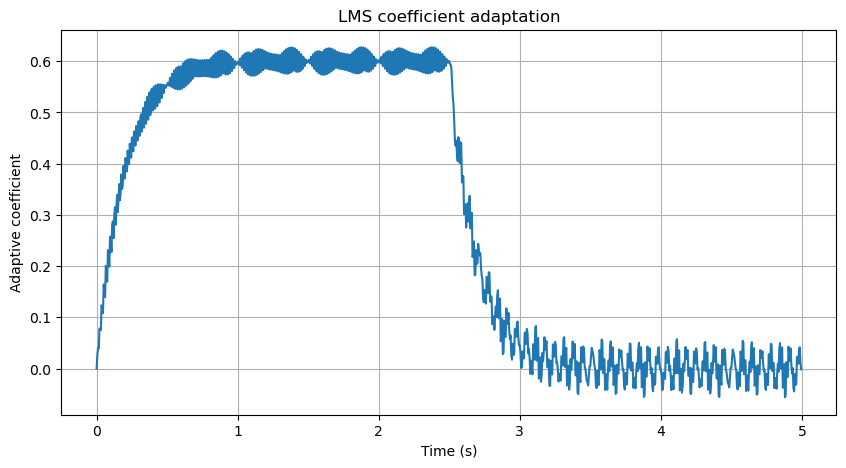

In [18]:
mu = 0.05
w = 0.0
y_freq = np.zeros(N)
e_freq = np.zeros(N)
w_history_freq = np.zeros(N)
plt.figure(figsize=(10, 5))
for n in range(N):
    y_freq[n] = w * x_ref[n]
    e_freq[n] = d_freq[n] - y_freq[n]
    w = w + mu * e_freq[n] * x_ref[n]
    w_history_freq[n] = w
plt.plot(t, w_history_freq)
plt.xlabel("Time (s)")
plt.ylabel("Adaptive coefficient")
plt.title("LMS coefficient adaptation")
plt.grid(True)
plt.show()

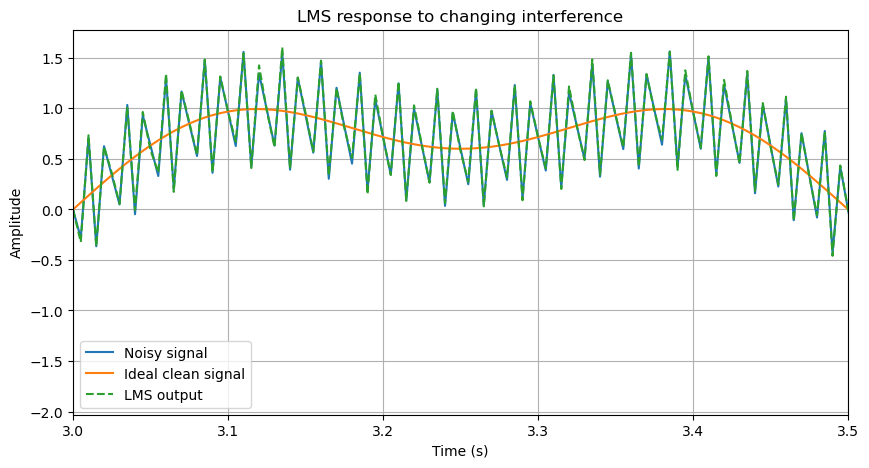

In [25]:
plt.figure(figsize=(10, 5))
plt.plot(t, d_freq, label="Noisy signal")
plt.plot(t, clean, label="Ideal clean signal")
plt.plot(t, e_freq, label="LMS output", linestyle="--")
plt.xlabel("Time (s)")
plt.legend()
plt.xlim(3, 3.5)
plt.ylabel("Amplitude")
plt.title("LMS response to changing interference")
plt.grid(True)
plt.show()

The green LMS output completely overlaps the blue noisy signal, this is because after adaptation, the coefficient becomes approximately 0

Therefore, e[n] = d[n]

        The LMS filter is no longer effectively removing the interference

Now I will test whether LMS can remove interference when the motor frequency changes and the reference follows that change

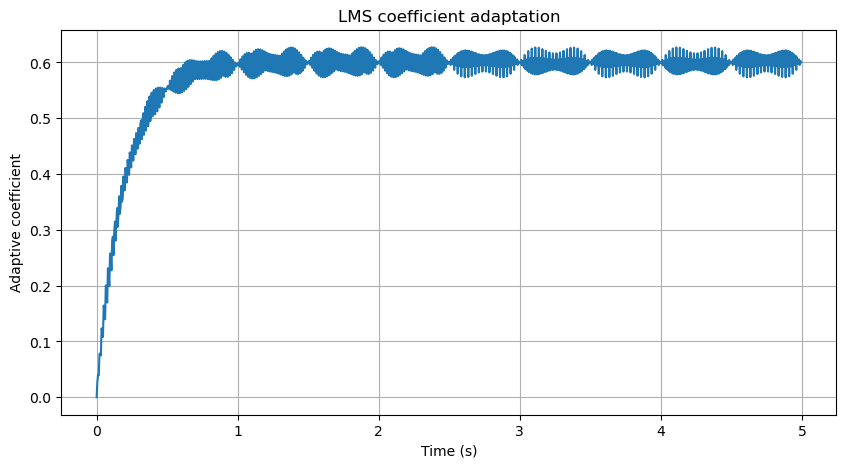

In [26]:
# New reference that tracks motor frequency
x_ref_track = np.sin(phase)
# Keep the same noisy measurement
d_track = d_freq

mu = 0.05
w = 0.0
y_track = np.zeros(N)
e_track = np.zeros(N)
w_history_track = np.zeros(N)
for n in range(N):
    y_track[n] = w * x_ref_track[n]
    e_track[n] = d_track[n] - y_track[n]
    w = w + mu * e_track[n] * x_ref_track[n]
    w_history_track[n] = w
plt.figure(figsize=(10, 5))
plt.plot(t, w_history_track)
plt.xlabel("Time (s)")
plt.ylabel("Adaptive coefficient")
plt.title("LMS coefficient adaptation")
plt.grid(True)
plt.show()

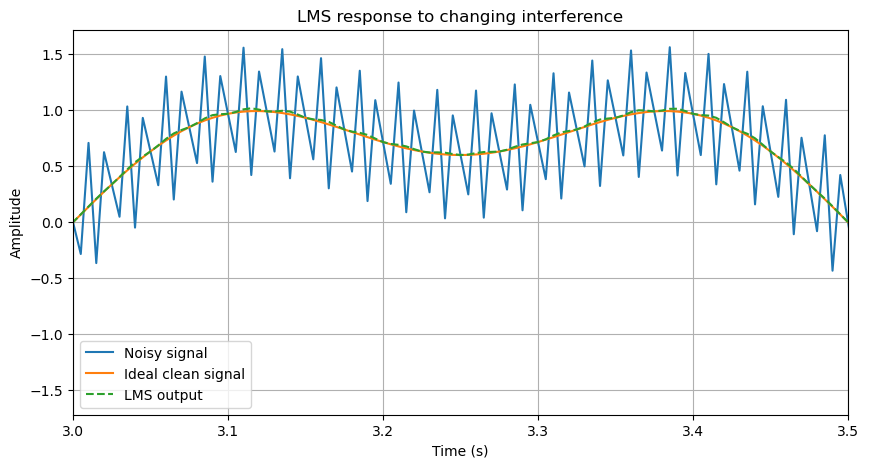

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(t, d_track, label="Noisy signal")
plt.plot(t, clean, label="Ideal clean signal")
plt.plot(t, e_track, label="LMS output", linestyle="--")
plt.xlabel("Time (s)")
plt.legend()
plt.xlim(3, 3.5)
plt.ylabel("Amplitude")
plt.title("LMS response to changing interference")
plt.grid(True)
plt.show()

This is much better now!

#### Next situation:

    What if the motor sensor has a phase difference?
    

##### Frequency Tracking with a Phase-Shifted Reference

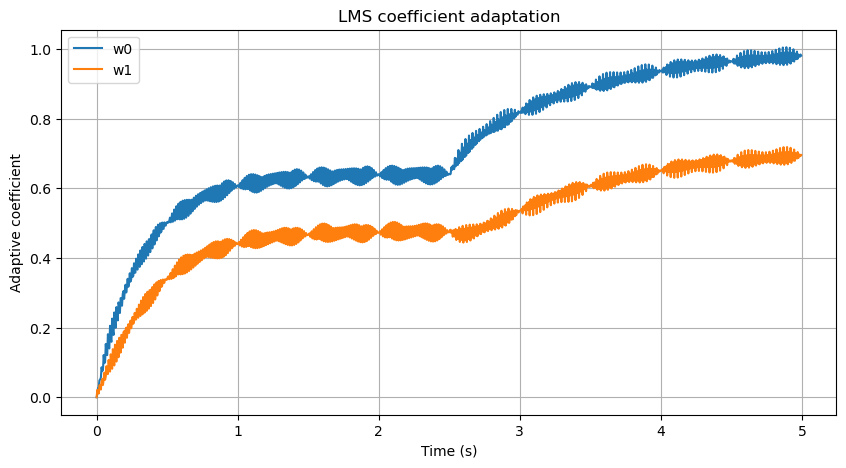

In [31]:
# Reference follows motor frequency,
# but has a 45-degree phase difference
x_ref_shifted = np.sin(phase + np.pi/4)
# Actual interference remains unchanged 
noise = 0.6 * np.sin(phase)
d_shifted = clean + noise

mu = 0.05
w = np.zeros(2)
y_multi = np.zeros(N)
e_multi = np.zeros(N)
w_history_multi = np.zeros((N, 2))
plt.figure(figsize=(10, 5))
for n in range(1, N):
    x_vector = np.array([x_ref_shifted[n], x_ref_shifted[n-1]])
    y_multi[n] = np.dot(w, x_vector)
    e_multi[n] = d_shifted[n] - y_multi[n]
    w = w + mu * e_multi[n] * x_vector
    w_history_multi[n] = w
plt.plot(t, w_history_multi[:, 0], label="w0")
plt.plot(t, w_history_multi[:, 1], label="w1")
plt.xlabel("Time (s)")
plt.ylabel("Adaptive coefficient")
plt.title("LMS coefficient adaptation")
plt.legend()
plt.grid(True)
plt.show()

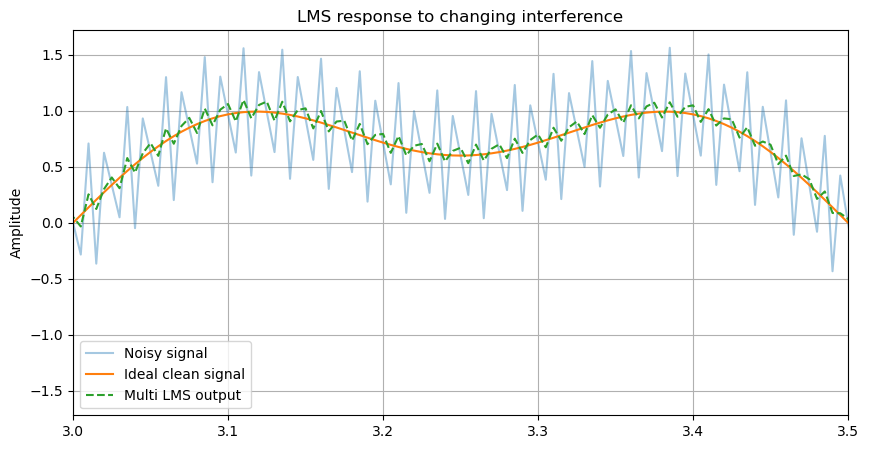

In [33]:
plt.figure(figsize=(10, 5))
plt.plot(t, d_shifted, label="Noisy signal", alpha=0.4)
plt.plot(t, clean, label="Ideal clean signal")
plt.plot(t, e_multi, label="Multi LMS output", linestyle="--")
plt.xlim(3, 3.5)
plt.ylabel("Amplitude")
plt.title("LMS response to changing interference")
plt.grid(True)
plt.legend()
plt.show()

In [34]:
periods = [("Before frequency change", 1.5, 2.5), ("After frequency change", 3.0, 5.0)]

for name, start, end in periods:
    mask = (t >= start) & (t < end)
    rmse = np.sqrt(np.mean((e_multi[mask] - clean[mask])**2))
    print(f"{name}: RMSE = {rmse:.4f}")

Before frequency change: RMSE = 0.0211
After frequency change: RMSE = 0.0482


This two-tap LMS filter successfully handles changing interference frequency when the reference follows that frequency, even with a phase difference.

## Conclusion

Adaptive filtering depends not only on the LMS algorithm but also on having a suitable reference signal, choosing an appropriate number of taps, and balancing adaptation speed against steady-state accuracy.